In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
import os

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.19.0


In [ ]:
dataset_path = r"C:\Users\SURAJ CHOUGULE\Downloads\Pneumonia X Ray-20221031T100017Z-001\Pneumonia X Ray"

train_path = dataset_path + "/train"
val_path = dataset_path + "/val"
test_path = dataset_path + "/test"

In [ ]:
datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(
    train_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="binary"
)

val_data = datagen.flow_from_directory(
    val_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="binary"
)

test_data = datagen.flow_from_directory(
    test_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

class_names = list(train_data.class_indices.keys())

print("Classes:", class_names)

Found 3937 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


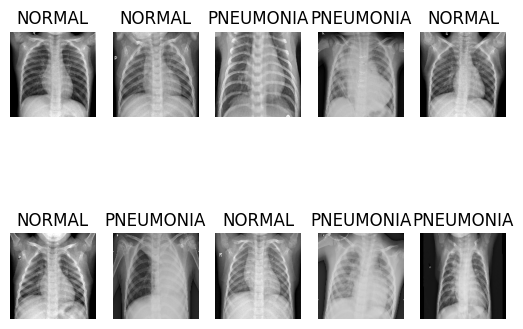

In [ ]:
images, labels = next(train_data)

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(images[i])
    plt.title(class_names[int(labels[i])])
    plt.axis('off')

plt.show()

Text(0.5, 1.0, 'NORMAL')

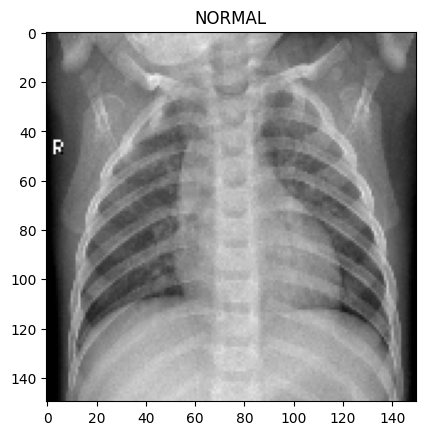

In [ ]:
plt.imshow(images[1])
plt.title(class_names[int(labels[1])])

In [ ]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.summary()

c:\Users\SURAJ CHOUGULE\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,481 (40.57 MB)

 Trainable params: 10,636,481 (40.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_data,
    epochs=5,
    validation_data=val_data
)

c:\Users\SURAJ CHOUGULE\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 103s 808ms/step - accuracy: 0.7939 - loss: 1.0564 - val_accuracy: 0.7500 - val_loss: 0.6050
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 80s 645ms/step - accuracy: 0.9632 - loss: 0.1115 - val_accuracy: 0.8125 - val_loss: 0.4041
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 90s 728ms/step - accuracy: 0.9739 - loss: 0.0806 - val_accuracy: 0.8125 - val_loss: 0.2833
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 88s 707ms/step - accuracy: 0.9812 - loss: 0.0549 - val_accuracy: 0.9375 - val_loss: 0.0830
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 80s 645ms/step - accuracy: 0.9805 - loss: 0.0501 - val_accuracy: 0.9375 - val_loss: 0.0790


In [ ]:
loss, acc = model.evaluate(test_data)

print("Test Accuracy:", acc)
print("Test Loss:", loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 415ms/step - accuracy: 0.5838 - loss: 2.1361
Test Accuracy: 0.7676281929016113
Test Loss: 1.2203705310821533


In [ ]:
test_data.reset()

pred = model.predict(test_data)

pred_classes = (pred > 0.5).astype(int).flatten()

print("Actual:", test_data.classes[:10])
print("Predicted:", pred_classes[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 376ms/step
Actual: [0 0 0 0 0 0 0 0 0 0]
Predicted: [0 1 1 1 1 0 0 1 0 1]


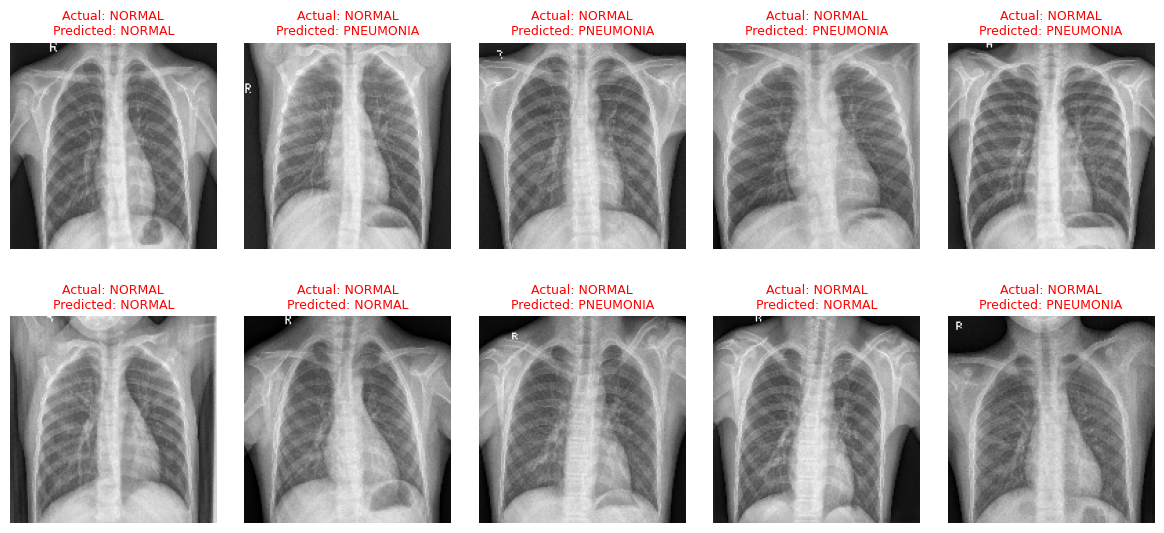

In [ ]:
test_data.reset()
images, labels = next(test_data)

plt.figure(figsize=(12, 6))

for i in range(10):
    actual = int(labels[i])
    pred = pred_classes[i]

    plt.subplot(2, 5, i+1)
    plt.imshow(images[i])


    plt.title(f"Actual: {class_names[actual]}\nPredicted: {class_names[pred]}",
              color=color, fontsize=9)

    plt.axis('off')

plt.tight_layout(pad=2)
plt.show()

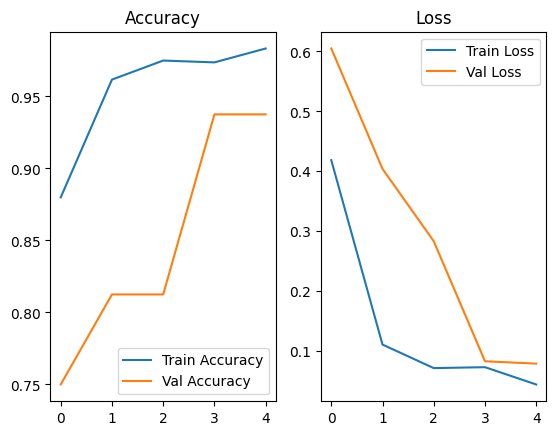

In [ ]:
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

plt.show()